# Practical Assignment 6: ClusteringAlgorithms

## 1. Import Libraries

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Dataset

In [5]:
# Keep Mall_Customers.csv in the same folder as this notebook.
# If your downloaded file has a different name, update the filename below.
import os
csv_candidates = ["Mall_Customers.csv"]
csv_path = next((name for name in csv_candidates if os.path.exists(name)), None)
if csv_path is None:
    raise FileNotFoundError(
        "Mall customer CSV not found. Download Mall_Customers.csv and place it beside this notebook."
    )

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Loaded file: Mall_Customers.csv
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


## 3. Inspect and Clean Data

In [7]:
print("Data types and non-null counts:")
df.info()

print("\nMissing values before cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe(include="all").T)

# Remove duplicate records, if any.
df = df.drop_duplicates().reset_index(drop=True)

feature_cols = ["Annual Income (k$)", "Spending Score (1-100)"]
missing_cols = [c for c in feature_cols if c not in df.columns]
if missing_cols:
    raise ValueError(
        f"Required columns not found: {missing_cols}. Please use the standard Mall_Customers.csv dataset."
    )

# Convert clustering features to numeric; invalid values become missing and are imputed with the median.
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

before_rows = len(df)
df = df.dropna(subset=feature_cols, how="all").reset_index(drop=True)
X_raw = df[feature_cols].copy()
X_raw = X_raw.fillna(X_raw.median(numeric_only=True))

print("\nRows removed as unusable:", before_rows - len(df))
print("Rows after cleaning:", len(df))
print("Missing clustering-feature values after cleaning:")
display(X_raw.isnull().sum().to_frame("Missing Values"))
if len(X_raw) < 3:
    raise ValueError("At least three usable customer records are required for clustering.")

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values before cleaning:


,Missing Values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate rows: 0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Rows removed as unusable: 0
Rows after cleaning: 200
Missing clustering-feature values after cleaning:


,Missing Values
Annual Income (k$),0
Spending Score (1-100),0


## 4. Exploratory Data Analysis (EDA)

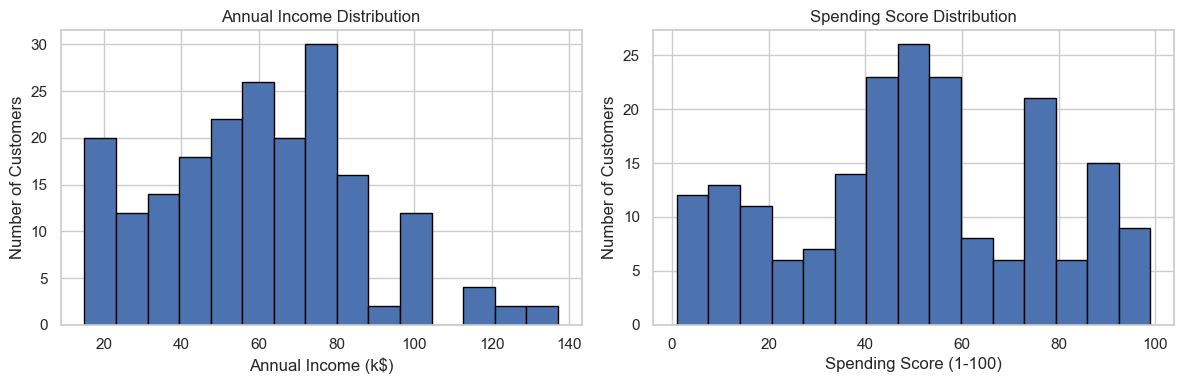

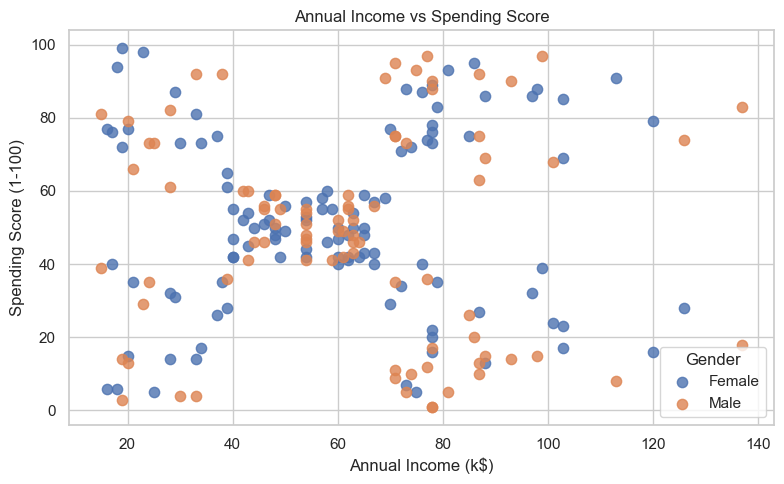

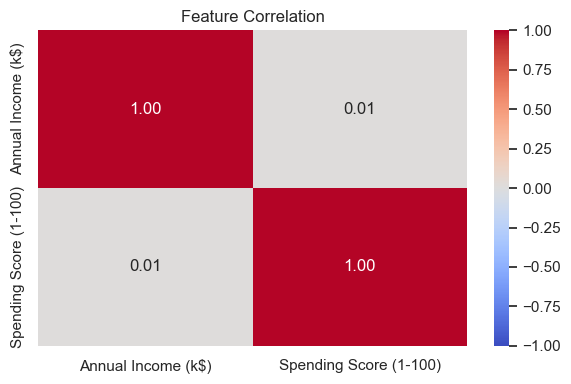

In [9]:
# Distribution plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Annual Income (k$)"].dropna(), bins=15, edgecolor="black")
axes[0].set_title("Annual Income Distribution")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Number of Customers")

axes[1].hist(df["Spending Score (1-100)"].dropna(), bins=15, edgecolor="black")
axes[1].set_title("Spending Score Distribution")
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Customer income vs spending score
plt.figure(figsize=(8, 5))
if "Gender" in df.columns:
    for gender, group in df.groupby("Gender"):
        plt.scatter(
            group["Annual Income (k$)"],
            group["Spending Score (1-100)"],
            label=gender,
            s=55,
            alpha=0.8
        )
    plt.legend(title="Gender")
else:
    plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], s=55, alpha=0.8)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

# Correlation between the selected numeric clustering features
plt.figure(figsize=(6, 4))
sns.heatmap(X_raw.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

## 5. Preprocessing

In [11]:
# Standardize the two selected features so both contribute comparably.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Features used:", feature_cols)
print("Scaled data shape:", X_scaled.shape)

Features used: ['Annual Income (k$)', 'Spending Score (1-100)']
Scaled data shape: (200, 2)


## 6. Select K for K-Means

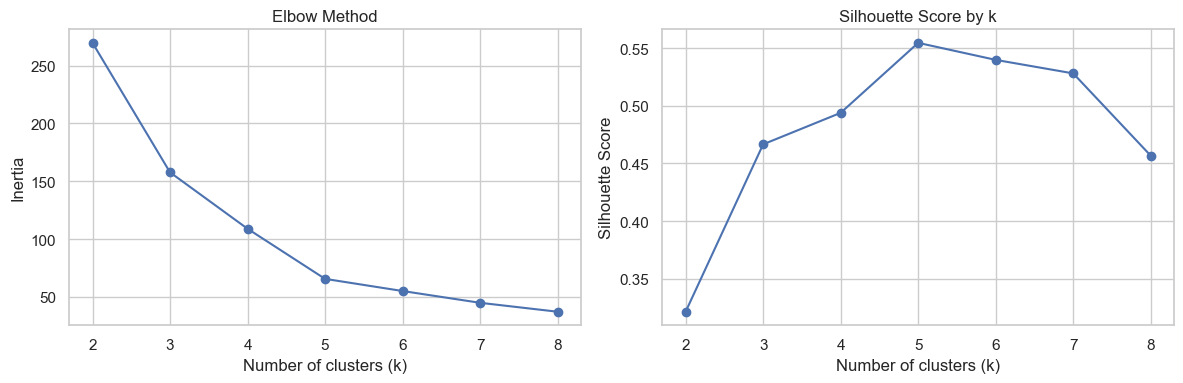

,k,Inertia,Silhouette Score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.1481,0.4567


Selected K based on highest tested silhouette score: 5


In [44]:
max_k = min(8, len(X_scaled) - 1)
k_values = range(2, max_k + 1)
inertias = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_values), silhouette_values, marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

k_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_values
})
display(k_results.round(4))

# Select the tested k with the highest silhouette score. Also inspect the elbow plot before final submission.
K = int(k_results.loc[k_results["Silhouette Score"].idxmax(), "k"])
print("Selected K based on highest tested silhouette score:", K)

## 7. Fit K-Means and Hierarchical Clustering

In [15]:
kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=20)
labels_kmeans = kmeans.fit_predict(X_scaled)

hierarchical = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_hierarchical = hierarchical.fit_predict(X_scaled)

print("K-Means clusters:", len(set(labels_kmeans)))
print("Hierarchical clusters:", len(set(labels_hierarchical)))

K-Means clusters: 5
Hierarchical clusters: 5


## 8. DBSCAN Parameter Tuning

DBSCAN labels noise observations as `-1`. The tuning loop evaluates multiple `eps` values and records cluster count, noise percentage, Silhouette Score, and Davies–Bouldin Index. The two metrics are calculated on non-noise observations only when at least two clusters remain.

The selection rule prefers at least two clusters and no more than 30% noise, then chooses the candidate with the highest Silhouette Score. If none meet the noise preference, it chooses the best valid multi-cluster candidate and reports the limitation.

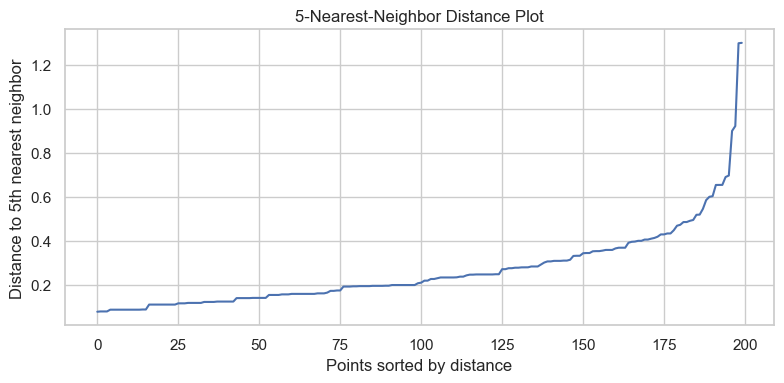

,eps,min_samples,Clusters,Noise Points,Noise (%),Silhouette Score,Davies-Bouldin Index
0,0.15,5,6,117,58.5,0.3684,0.5904
1,0.20,5,7,77,38.5,0.5856,0.4637
2,0.25,5,6,50,25.0,0.5317,0.5580
3,0.30,5,7,35,17.5,0.5243,0.5800
4,0.35,5,6,23,11.5,0.5577,0.5106
5,0.40,5,4,15,7.5,0.4781,0.5912
6,0.45,5,3,11,5.5,0.3536,0.7361
7,0.50,5,2,8,4.0,0.3876,0.7889
8,0.60,5,1,5,2.5,NaN,NaN
9,0.70,5,1,0,0.0,NaN,NaN


In [17]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.title(f"{min_samples}-Nearest-Neighbor Distance Plot")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.tight_layout()
plt.show()

eps_values = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80]
dbscan_trials = []

for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels) - {-1})
    n_noise = int(np.sum(labels == -1))
    noise_pct = 100 * n_noise / len(labels)

    mask = labels != -1
    valid_labels = labels[mask]
    valid_X = X_scaled[mask]
    sil = np.nan
    dbi = np.nan

    if len(set(valid_labels)) >= 2 and len(valid_labels) > len(set(valid_labels)):
        sil = silhouette_score(valid_X, valid_labels)
        dbi = davies_bouldin_score(valid_X, valid_labels)

    dbscan_trials.append({
        "eps": eps,
        "min_samples": min_samples,
        "Clusters": n_clusters,
        "Noise Points": n_noise,
        "Noise (%)": noise_pct,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    })

dbscan_tuning = pd.DataFrame(dbscan_trials)
display(dbscan_tuning.round(4))

In [18]:
valid_trials = dbscan_tuning[
    (dbscan_tuning["Clusters"] >= 2) &
    dbscan_tuning["Silhouette Score"].notna()
].copy()

preferred_trials = valid_trials[valid_trials["Noise (%)"] <= 30].copy()

if not preferred_trials.empty:
    chosen_trial = preferred_trials.sort_values("Silhouette Score", ascending=False).iloc[0]
    selection_note = "Selected from candidates with at least 2 clusters and <=30% noise."
elif not valid_trials.empty:
    chosen_trial = valid_trials.sort_values("Silhouette Score", ascending=False).iloc[0]
    selection_note = "No candidate met the <=30% noise preference; selected the best valid multi-cluster candidate."
else:
    chosen_trial = dbscan_tuning.sort_values("Noise (%)", ascending=True).iloc[0]
    selection_note = "No tested candidate yielded at least two clusters; selected the candidate with the least noise."

best_eps = float(chosen_trial["eps"])
best_min_samples = int(chosen_trial["min_samples"])
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
labels_dbscan = dbscan.fit_predict(X_scaled)

print(f"Selected eps: {best_eps}")
print(f"Selected min_samples: {best_min_samples}")
print(selection_note)
print("Clusters:", len(set(labels_dbscan) - {-1}))
print("Noise points:", int(np.sum(labels_dbscan == -1)),
      f"({np.mean(labels_dbscan == -1) * 100:.2f}%)")

Selected eps: 0.35
Selected min_samples: 5
Selected from candidates with at least 2 clusters and <=30% noise.
Clusters: 6
Noise points: 23 (11.50%)


## 9. Evaluate Clustering Quality

In [20]:
def evaluate_clustering(X, labels, algorithm):
    labels = np.asarray(labels)
    if algorithm == "DBSCAN":
        noise_count = int(np.sum(labels == -1))
        n_clusters = len(set(labels) - {-1})
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
    else:
        noise_count = 0
        n_clusters = len(set(labels))
        X_eval = X
        labels_eval = labels

    sil = np.nan
    dbi = np.nan
    if len(set(labels_eval)) >= 2 and len(labels_eval) > len(set(labels_eval)):
        sil = silhouette_score(X_eval, labels_eval)
        dbi = davies_bouldin_score(X_eval, labels_eval)

    return {
        "Algorithm": algorithm,
        "Clusters": n_clusters,
        "Noise Points": noise_count,
        "Noise (%)": noise_count / len(labels) * 100,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    }

results = [
    evaluate_clustering(X_scaled, labels_kmeans, "K-Means"),
    evaluate_clustering(X_scaled, labels_hierarchical, "Hierarchical"),
    evaluate_clustering(X_scaled, labels_dbscan, "DBSCAN")
]

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4).style.hide(axis="index"))

Algorithm,Clusters,Noise Points,Noise (%),Silhouette Score,Davies-Bouldin Index
K-Means,5,0,0.000000,0.554700,0.572200
Hierarchical,5,0,0.000000,0.553800,0.577900
DBSCAN,6,23,11.500000,0.557700,0.510600


## 10. Visualize Clusters

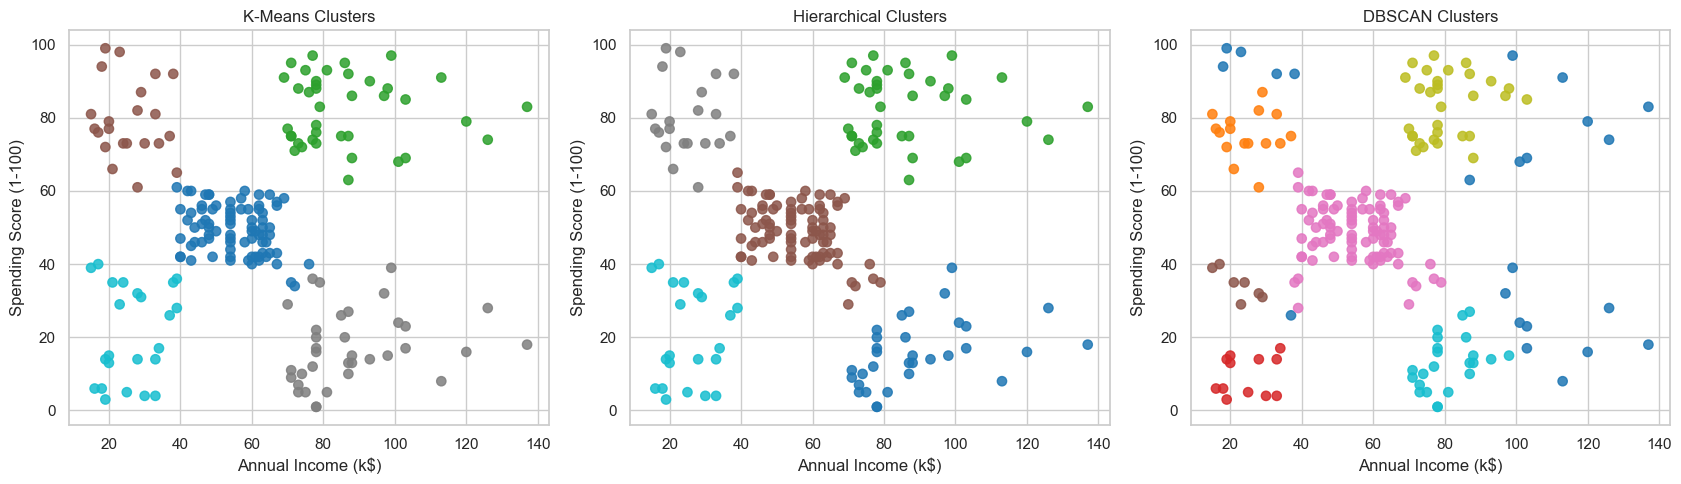

In [22]:
# The selected features have two dimensions, so they can be plotted directly.
labels_for_plot = {
    "K-Means": labels_kmeans,
    "Hierarchical": labels_hierarchical,
    "DBSCAN": labels_dbscan
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, labels) in zip(axes, labels_for_plot.items()):
    scatter = ax.scatter(
        X_raw["Annual Income (k$)"],
        X_raw["Spending Score (1-100)"],
        c=labels,
        cmap="tab10",
        s=45,
        alpha=0.85
    )
    ax.set_title(f"{name} Clusters")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

## 11. Customer Segment Profiles

In [24]:
profile_df = df.copy()
profile_df["KMeans_Cluster"] = labels_kmeans

print("Customers per K-Means cluster:")
display(profile_df["KMeans_Cluster"].value_counts().sort_index().to_frame("Customer Count"))

print("Average age, annual income, and spending score by cluster:")
profile_cols = [c for c in ["Age", "Annual Income (k$)", "Spending Score (1-100)"] if c in profile_df.columns]
display(profile_df.groupby("KMeans_Cluster")[profile_cols].mean().round(2))

if "Gender" in profile_df.columns:
    print("Gender composition by K-Means cluster (row proportions):")
    display(pd.crosstab(
        profile_df["KMeans_Cluster"], profile_df["Gender"], normalize="index"
    ).round(3))

Customers per K-Means cluster:


,Customer Count
KMeans_Cluster,
0,81
1,39
2,22
3,35
4,23


Average age, annual income, and spending score by cluster:


,Age,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


Gender composition by K-Means cluster (row proportions):


Gender,Female,Male
KMeans_Cluster,,
0,0.593,0.407
1,0.538,0.462
2,0.591,0.409
3,0.457,0.543
4,0.609,0.391


## 12. Final Algorithm Comparison

In [26]:
final_comparison = pd.DataFrame(results)

columns_to_show = [
    "Algorithm", "Clusters", "Noise Points", "Noise (%)",
    "Silhouette Score", "Davies-Bouldin Index"
]

display(
    final_comparison.loc[:, columns_to_show]
    .reset_index(drop=True)
    .style.format({
        "Noise (%)": "{:.2f}",
        "Silhouette Score": "{:.4f}",
        "Davies-Bouldin Index": "{:.4f}"
    })
    .hide(axis="index")
)

valid_sil = final_comparison.dropna(subset=["Silhouette Score"])
if not valid_sil.empty:
    row = valid_sil.loc[valid_sil["Silhouette Score"].idxmax()]
    print(f"Highest Silhouette Score: {row['Algorithm']} ({row['Silhouette Score']:.4f})")

valid_dbi = final_comparison.dropna(subset=["Davies-Bouldin Index"])
if not valid_dbi.empty:
    row = valid_dbi.loc[valid_dbi["Davies-Bouldin Index"].idxmin()]
    print(f"Lowest Davies-Bouldin Index: {row['Algorithm']} ({row['Davies-Bouldin Index']:.4f})")

Algorithm,Clusters,Noise Points,Noise (%),Silhouette Score,Davies-Bouldin Index
K-Means,5,0,0.00,0.5547,0.5722
Hierarchical,5,0,0.00,0.5538,0.5779
DBSCAN,6,23,11.50,0.5577,0.5106


Highest Silhouette Score: DBSCAN (0.5577)
Lowest Davies-Bouldin Index: DBSCAN (0.5106)


## 13. Export Cluster Labels and Comparison Results

Save the customer-level cluster assignments and the algorithm comparison table as CSV files. These files can be used in the report or presentation.

In [28]:
# Export customer-level assignments (includes original columns plus cluster labels).
customer_results = df.copy()
customer_results["KMeans_Cluster"] = labels_kmeans
customer_results["Hierarchical_Cluster"] = labels_hierarchical
customer_results["DBSCAN_Cluster"] = labels_dbscan
customer_results.to_csv("Mall_Customer_Cluster_Labels.csv", index=False)

# Export algorithm evaluation table.
final_comparison = pd.DataFrame(results)
final_comparison.to_csv("Mall_Clustering_Algorithm_Comparison.csv", index=False)

print("Saved: Mall_Customer_Cluster_Labels.csv")
print("Saved: Mall_Clustering_Algorithm_Comparison.csv")
display(final_comparison.round(4))

Saved: Mall_Customer_Cluster_Labels.csv
Saved: Mall_Clustering_Algorithm_Comparison.csv


,Algorithm,Clusters,Noise Points,Noise (%),Silhouette Score,Davies-Bouldin Index
0,K-Means,5,0,0.0,0.5547,0.5722
1,Hierarchical,5,0,0.0,0.5538,0.5779
2,DBSCAN,6,23,11.5,0.5577,0.5106
